# Actividad 1 

## Cargar la base de datos

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

Tenemos problemas al hacer parse a la columna fechas. El comando usual de "`pm25= pd.read_csv(ruta, parse_dates=["fecha"])`" tiene problemas para hacer las fechas en formado `"%d/%m/%y"`

In [2]:
ruta= "https://raw.githubusercontent.com/jamc88/TSMA-II-26-O/refs/heads/main/Datos/PM25_promedio_diario_2020_2025.csv"

pm25=pd.read_csv(ruta) # Tenemos problemas con parse

pm25["fecha"].head(20)

0     01/01/20
1     02/01/20
2     03/01/20
3     04/01/20
4     05/01/20
5     06/01/20
6     07/01/20
7     08/01/20
8     09/01/20
9     10/01/20
10    11/01/20
11    12/01/20
12    13/01/20
13    14/01/20
14    15/01/20
15    16/01/20
16    17/01/20
17    18/01/20
18    19/01/20
19    20/01/20
Name: fecha, dtype: str

In [3]:
# Valores únicos de formato
print(pm25["fecha"].unique())

<StringArray>
['01/01/20', '02/01/20', '03/01/20', '04/01/20', '05/01/20', '06/01/20',
 '07/01/20', '08/01/20', '09/01/20', '10/01/20',
 ...
 '22/12/25', '23/12/25', '24/12/25', '25/12/25', '26/12/25', '27/12/25',
 '28/12/25', '29/12/25', '30/12/25', '31/12/25']
Length: 2192, dtype: str


Formato DD/MM/YYYY

De forma explícita, queremos formato `"%d/%m/%y"`

In [4]:
pm25["fecha"]= pd.to_datetime(pm25["fecha"],format="%d/%m/%y")


In [5]:
pm25["fecha"].unique()

<DatetimeArray>
['2020-01-01 00:00:00', '2020-01-02 00:00:00', '2020-01-03 00:00:00',
 '2020-01-04 00:00:00', '2020-01-05 00:00:00', '2020-01-06 00:00:00',
 '2020-01-07 00:00:00', '2020-01-08 00:00:00', '2020-01-09 00:00:00',
 '2020-01-10 00:00:00',
 ...
 '2025-12-22 00:00:00', '2025-12-23 00:00:00', '2025-12-24 00:00:00',
 '2025-12-25 00:00:00', '2025-12-26 00:00:00', '2025-12-27 00:00:00',
 '2025-12-28 00:00:00', '2025-12-29 00:00:00', '2025-12-30 00:00:00',
 '2025-12-31 00:00:00']
Length: 2192, dtype: datetime64[us]

In [6]:
print(pm25.dtypes)


fecha            datetime64[us]
PM25_promedio           float64
dtype: object


Base de datos con columnas que representas las variables:
- `fecha` es columna tipo `datetime64`
- `PM25_promedio` es columna tipo `float64`

Ahora ordenamos el DataFrame por columna fecha, reiniciando el índice.




In [7]:
pm25.sort_values("fecha").reset_index(drop=True)
pm25

,fecha,PM25_promedio
0,2020-01-01,31.281250
1,2020-01-02,6.357639
2,2020-01-03,10.484375
3,2020-01-04,30.875000
4,2020-01-05,21.437500
...,...,...
2187,2025-12-27,19.552083
2188,2025-12-28,21.864583
2189,2025-12-29,18.614583
2190,2025-12-30,14.864583


## Caracteristicas de DataFrame



In [8]:
print(f"Dimensiones del DataFrame: {pm25.shape}")

print(f"\nColumnas: {pm25.columns.tolist()}")

print(f"\nPeriodo: { pm25["fecha"].min() }  a {pm25["fecha"].max() }")

print(f"\nNúmero de observaciones: {len(pm25)}")

print(f"\nValores faltantes: {pm25.isna().sum().to_frame("n_faltantes")}")

Dimensiones del DataFrame: (2192, 2)

Columnas: ['fecha', 'PM25_promedio']

Periodo: 2020-01-01 00:00:00  a 2025-12-31 00:00:00

Número de observaciones: 2192

Valores faltantes:                n_faltantes
fecha                    0
PM25_promedio            0


## Visualización de la serie

La visualización nos permite identificar: cambios de nivel a largo plazo, periodos con altas concentraciones, patrones que se repiten entre años, cambios en la variabilidad y observaciones extremas.

In [9]:
pm25.head(2)

,fecha,PM25_promedio
0,2020-01-01,31.281250
1,2020-01-02,6.357639


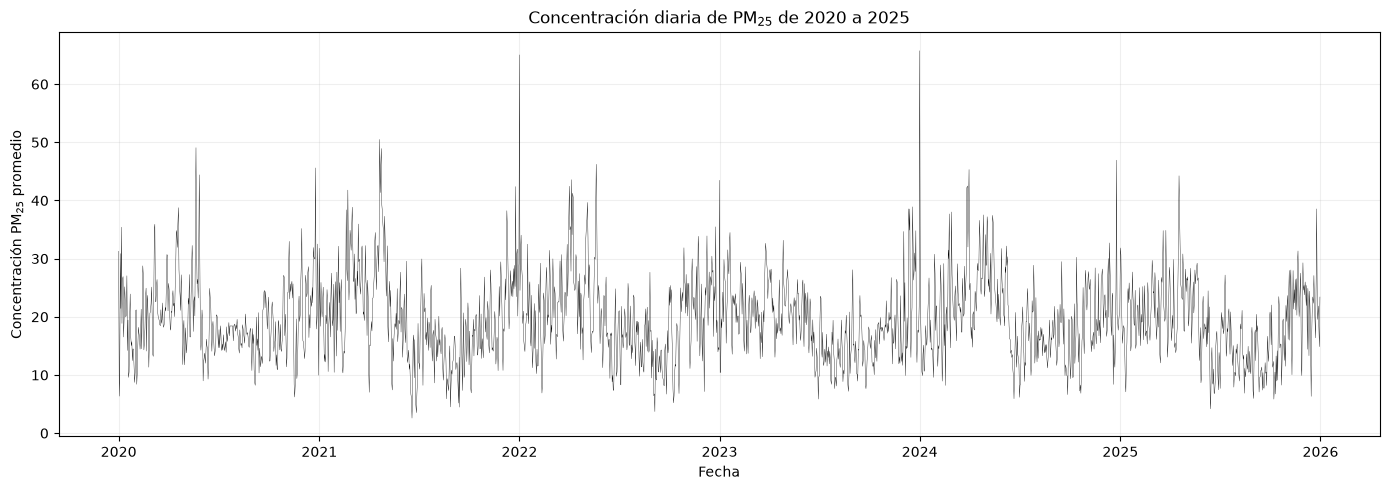

In [10]:

fig, ax= plt.subplots(figsize=(14,5))

ax.plot(
    pm25["fecha"],
    pm25["PM25_promedio"],
    linewidth= 0.25,
    color="black"   
)

ax.set_title("Concentración diaria de PM$_{25}$ de 2020 a 2025")
ax.set_xlabel("Fecha")
ax.set_ylabel("Concentración PM$_{25}$ promedio")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

#### Variabilidad
La concentración de PM$_{25}$ fluctua bastante con picos que superan concentraciones de $50\frac{\mu g}{m^3}$ a $60\frac{\mu g}{m^3}$ en los puntos más altos y bajan de los $10\frac{\mu g}{m^3}$. Se observan episodios de contaminación aguda intercalados con fechas con concentración baja o buena condición del aire (OMS recomienda límite de $25\frac{\mu g}{m^3}$ como promedio diario). 


#### Estacionalidad
Parece existir periodicidad anual con mayor concentración mayor en temporada invernal. Los picos de mayor concentración pueden estar relacionados con estaciones secas, incendios forestales, o mayor actividad industrial en ciertos meses.

#### Tendencia global
No se aprecia cambio sostenido a lo largo de los años, parace ser un fenonómeno persistente.

#### Consideraciones

Existe persistencia de valores altos en la concentración de PM$_{25}$ por sobre los niveles recomendados. Posible coincidencia de valores altos de concentración con temporadas invernales.


### Resumen descriptivo

In [11]:
print("Resumen de la serie diaria: ")
display( pm25["PM25_promedio"].describe().to_frame("PM25_promedio").round(2) )

# Valores extremos. idxmax() devuelve el índice de la fila donde ocurre el valor máximo. loc[...] recupera esa fila completa.
fila_max=pm25.loc[ pm25["PM25_promedio"].idxmax()  ]
# idmin() devuelve el índice de la fila donde ocurre el valor mínimo. loc[...] recupera esa fila completa.
fila_min= pm25.loc[ pm25["PM25_promedio"].idxmin() ]

print(f"\nMáximo diario: \n{fila_max}")

print(f"\nMínimo diario: \n{fila_min}")

Resumen de la serie diaria: 


,PM25_promedio
count,2192.00
mean,19.51
std,7.08
min,2.58
25%,14.60
50%,18.73
75%,23.67
max,65.75



Máximo diario: 
fecha            2024-01-01 00:00:00
PM25_promedio                  65.75
Name: 1461, dtype: object

Mínimo diario: 
fecha            2021-06-19 00:00:00
PM25_promedio               2.583333
Name: 535, dtype: object


## Comparación del padrón anual

Para observar patrones estacionales anuales, graficamos la comparación de curvas anuales alineadas en un mismo calendario (enero-diciembre). Si existe estacionalidad se deberían observar patrones similares. 

El gráfico de comparación permite observar variabilidad interanual y estacionalidad del PM$_{25}$. En todos los años se observan picos altos en ciertas épocas y descensos en meses similares. Visualmente hay ciclos persistentes que se repiten cada año sin reducciones sostenidas.

In [12]:
pm25.head(2)

,fecha,PM25_promedio
0,2020-01-01,31.281250
1,2020-01-02,6.357639


In [13]:
# Calendario
pm25["anio"]=pm25["fecha"].dt.year
pm25["mes"]=pm25["fecha"].dt.month
pm25["dia"]=pm25["fecha"].dt.day

# Nueva columna `fecha_calendario`  de referencia.
pm25["fecha_calendario"]= pd.to_datetime("2000-"+pm25["fecha"].dt.strftime("%m-%d"))
pm25.head(2)

,fecha,PM25_promedio,anio,mes,dia,fecha_calendario
0,2020-01-01,31.281250,2020,1,1,2000-01-01
1,2020-01-02,6.357639,2020,1,2,2000-01-02


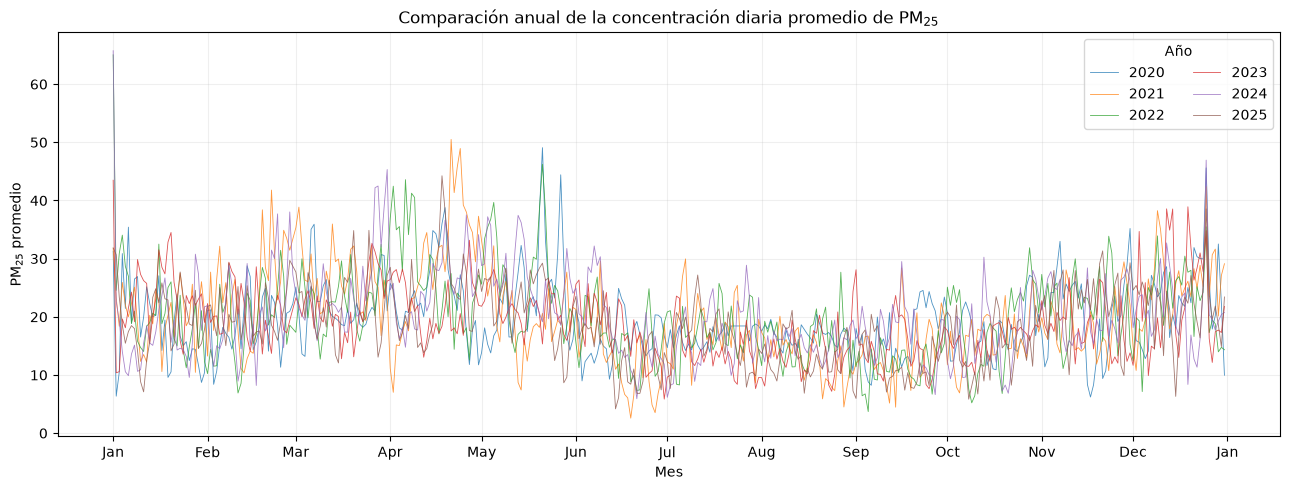

In [14]:
import matplotlib.dates as mdates

fig,ax=plt.subplots(figsize=(13,5))

# Se itera para cada año y datos por año. `anio` da años 2020-2025, `datos_anio` da el dataframe por año
for anio,datos_anio in pm25.groupby("anio"):

    ax.plot(
        datos_anio["fecha_calendario"],
        datos_anio["PM25_promedio"],
        linewidth= 0.6,
        alpha=0.8,
        label=str(anio)
    )
# Etiquetas
ax.xaxis.set_major_locator( mdates.MonthLocator() )  # marcas principales en el eje X en cada inicio de mes.
ax.xaxis.set_major_formatter( mdates.DateFormatter("%b") )  # etiquetas como abreviaturas del mes
ax.set_title("Comparación anual de la concentración diaria promedio de PM$_{25}$")
ax.set_xlabel("Mes")
ax.set_ylabel("PM$_{25}$ promedio")
ax.legend(title= "Año",ncol=2)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

## Perfil mensual del PM$_{25}$

El gráfico anterior sugiere estacionalidad persistente. Para visualizar la estructura estacional suavizaremos la variabilidad. 

#### Promedio mensual por año
Agrupamos datos de PM$_{25}$ por mes y año. Calculamos el promedio mensual de concentración diaria (`PM25_promedio`), creamos un nuevo DataFrame.

In [15]:
perfil_mensual_anual=(
    pm25
    .groupby( ["anio","mes"],as_index=False )
    .agg( PM25_promedio_mensual=("PM25_promedio","mean") )
)

perfil_mensual_anual


,anio,mes,PM25_promedio_mensual
0,2020,1,18.581177
1,2020,2,18.608390
2,2020,3,22.219758
3,2020,4,23.916319
4,2020,5,23.988911
...,...,...,...
67,2025,8,13.032594
68,2025,9,12.349997
69,2025,10,14.744122
70,2025,11,22.466667


#### Perfil mensual global
Se calcula el perfil mensual global de la concentración de PM$_{25}$ considerando todos los años entre 2020 y 2025. Creamos un nuevo DataFrame el la información extraída del DataFrame original.

In [16]:
# Perfil mensual global 2020-2025

perfil_mensual_global= (
    pm25
    .groupby("mes",as_index=False)
    .agg( media= ("PM25_promedio","mean"), mediana=("PM25_promedio","median"), desv_std=("PM25_promedio","std") )
)

print("Perfil mensual global: ")
perfil_mensual_global



Perfil mensual global: 


,mes,media,mediana,desv_std
0,1,20.461345,19.802083,7.866108
1,2,20.513475,19.767228,6.367541
2,3,23.566746,22.593750,5.813825
3,4,25.171050,24.515514,7.817862
4,5,23.388143,22.864583,6.842621
5,6,15.772894,15.656250,5.740563
6,7,16.445625,16.519583,4.500061
7,8,14.595197,14.723958,3.657454
8,9,14.422300,14.151042,4.923251
9,10,16.564552,16.776042,5.202955


In [17]:
pm25.head(2)

,fecha,PM25_promedio,anio,mes,dia,fecha_calendario
0,2020-01-01,31.281250,2020,1,1,2000-01-01
1,2020-01-02,6.357639,2020,1,2,2000-01-02


<function matplotlib.pyplot.show(close=None, block=None)>

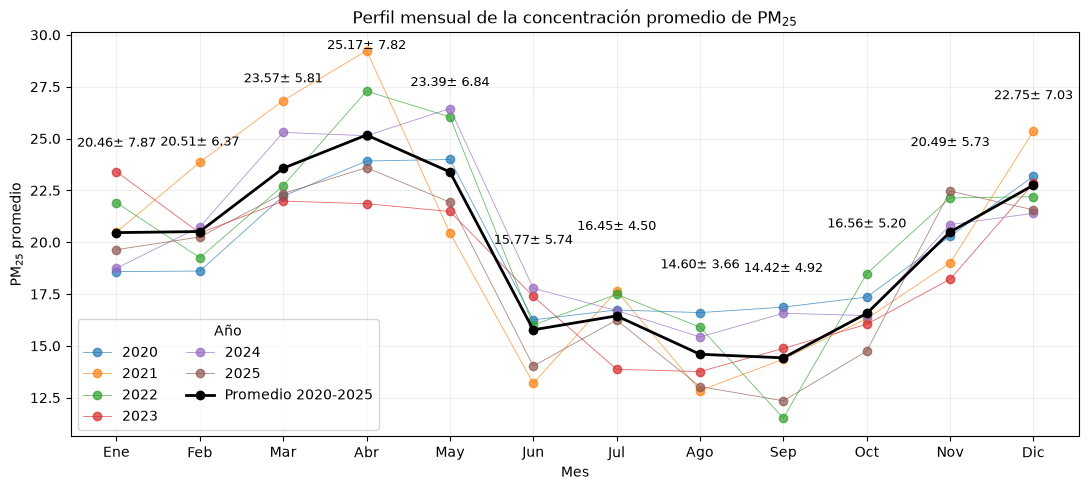

In [18]:
meses= ["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"]

fig,ax= plt.subplots(figsize=(11,5))

# Perfil de cada año
for anio, datos in perfil_mensual_anual.groupby("anio"):
    ax.plot(
        datos["mes"],
        datos["PM25_promedio_mensual"],
        marker="o",
        linewidth=0.6,
        alpha=0.7,
        label=str(anio)
    )

# Perfil promedio de los seis años
ax.plot(
    perfil_mensual_global["mes"],
    perfil_mensual_global["media"],
    marker="o",
    linewidth=2,
    label="Promedio 2020-2025",
    color="black"
)

# Poner promedio de los seis años
for i,j in enumerate(perfil_mensual_global["media"]):
    ax.text(
        i+1,
        j+4,
        f"{j:.2f}± {perfil_mensual_global["desv_std"][i]:.2f}",
        fontsize=9,
        ha="center",
        va="bottom"
    )

ax.set_xticks(range(1,13))
ax.set_xticklabels(meses)

ax.set_title("Perfil mensual de la concentración promedio de PM$_{25}$")
ax.set_xlabel("Mes")
ax.set_ylabel("PM$_{25}$ promedio")
ax.legend(title="Año",ncol=2)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show

#### Patrones generales

**Estacionalidad**: se observan variaciones mensuales consistentes. Los valores tienden a ser más altos en ciertos meses (ej. abril, diciembre) y más bajos en otros (ej. agosto, septiembre).

**Promedio multianual**: la línea negra muestra el siguiente comportamiento: concentraciones relativamente altas al inicio del año (~20–25 µg/m³), descenso hacia mediados (~14 µg/m³ en junio), y repunte hacia finales (~22–23 µg/m³ en diciembre).

**Variabilidad interna**: las barras de desviación estándar indican que, aunque hay un patrón claro, existe dispersión significativa dentro de cada mes, lo que refleja episodios puntuales de contaminación. Los meses de enero y diciembre presentan mayor desviación estandar.

Estos resultados proporcionan evidencia descriptiva de una **posible estacionalidad anual**.

Algunos años presentan picos más pronunciados en invierno, lo que puede estar asociado a condiciones meteorológicas adversas (inversión térmica, menor dispersión). Otros muestran meses tienen valores más moderados, pero el patrón de repunte invernal se mantiene. La consistencia del ciclo sugiere que las fuentes de emisión (tráfico, combustión residencial, industria) y las condiciones atmosféricas son recurrentes.

#### Salud pública
Exposición crónica: los valores mensuales promedio superan con frecuencia el límite recomendado por la OMS (15 µg/m³ como promedio anual), lo que implica riesgo sostenido para la salud respiratoria y cardiovascular. Enero, febrero y diciembre son meses con mayor concentración promedio de PM$_{25}$. La persistencia del patrón a lo largo de los años indica que las políticas y estrategia de control deberían consentrase en esos periodos.

## Distribución de PM$_{25}$ por mes

El promedio mensual resume niveles típicos de cada mes pero no muestra la distribución de las observaciones diarias. Usamos los diagramas de cajas por mes para identificar desplazamientos que indiquen evidencia de estacionalidad.

In [19]:
pm25.head(2)

,fecha,PM25_promedio,anio,mes,dia,fecha_calendario
0,2020-01-01,31.281250,2020,1,1,2000-01-01
1,2020-01-02,6.357639,2020,1,2,2000-01-02


La columna `mes` tiene como valores números (1-12), vamos a mapear estos números a cadenas de abreviaturas de los meses. Estos mapeos los guardamos en una nueva columna.

In [20]:
nombres_meses= {1:"Ene",2:"Feb",3:"Mar",4:"Abr",5:"May",6:"Jun",7:"Jul",8:"Ago",9:"Sep",10:"Oct",11:"Nov",12:"Dic"}

pm25["mes_nombre"]= pm25["mes"].map(nombres_meses)
orden_meses= list(nombres_meses.values())

pm25.head(2)

,fecha,PM25_promedio,anio,mes,dia,fecha_calendario,mes_nombre
0,2020-01-01,31.281250,2020,1,1,2000-01-01,Ene
1,2020-01-02,6.357639,2020,1,2,2000-01-02,Ene


#### Boxplot
El gráfico boxplot para esta serie temporal nos dará:
- La distribución de valores de PM$_{25}$ por mes.
- Variabilidad y posibles valores atípicos.

La comparación entre meses nos dará evidencia visual de patrones estacionales a través de las concentraciones. El gráfico nos permite analizar visualmente la variación mensual de PM$_{25}$


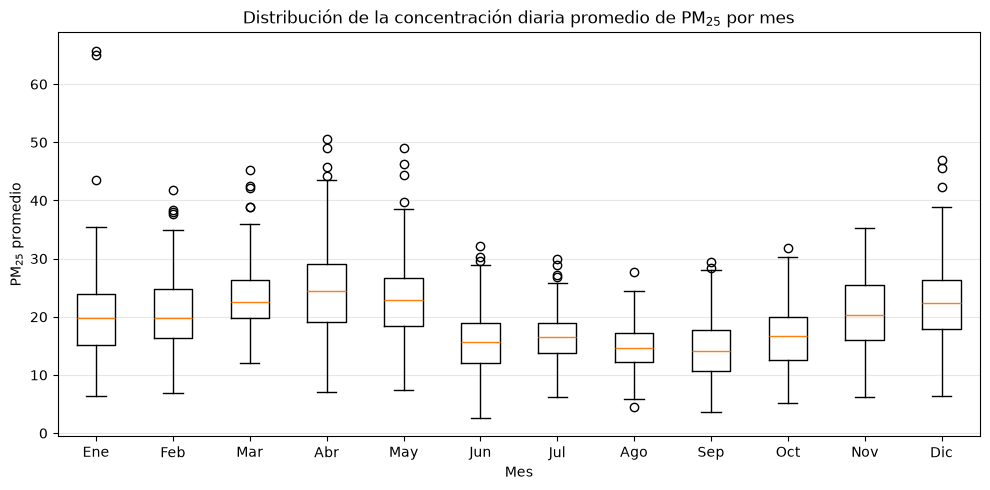

In [21]:
#Gráfico boxplot

fig,ax= plt.subplots(figsize=(10,5))

datos_boxplot=[]
for mes in orden_meses:
    datos_mes= pm25.loc[ pm25["mes_nombre"]==mes, "PM25_promedio" ]  # Nos da las filas correspondientes a cada mes
    datos_boxplot.append(datos_mes)    # Los guarda en lista datos_boxplot

ax.boxplot(
    datos_boxplot,
    tick_labels=orden_meses,
    showfliers=True
)

ax.set_title("Distribución de la concentración diaria promedio de PM$_{25}$ por mes")
ax.set_xlabel("Mes")
ax.set_ylabel("PM$_{25}$ promedio")
ax.grid(axis="y",alpha=0.3)

plt.tight_layout()
plt.show()

Las concentraciones diarias presentan valores altos en abril, enero y diciembre. Abril, noviembre presentan mayor variabilidad.

Las cajas boxplot nos dan una distribución de los datos.
- La línea central (mediana) indica el valor típico de concentración de PM$_{25}$ en ese mes.
- Caja ($\text{IQR}$: rango intercuartílico) concentra el 50% de los valores
- Bigotes. abarcan los valores dentro de 1.5 veces el IQR.
- Puntos fuera(outliers) días con concentraciones extremas, altas o bajas de lo habitual.

#### Estacionalidad
- Los meses como enero, febrero, diciembre tienden a mostrar medianas más altas y cajas más elevadas, lo que refleja mayor contaminación en esa época.
- Los meses de verano (junio, julio, agosto) presentan medianas más bajas y menor dispersión, indicando aire más limpio y estable.

#### Variabilidad intra-mensual
- Algunos meses como abril y noviembre tienen cajas muy grandes, esto indica que las concentraciones de PM$_{25}$ fluctuan mucho dentro del mismo mes.
- En contraste, meses como agosto tienen cajas mas compactas, reflejando condiciones más homogéneas
#### Outliers
- La presencia de puntos aislados en casi todos los meses indica episodios críticos de contaminación, posiblemente asociados a incendios, contingencias ambientales o condiciones meteorológicas adversas.

#### Comparación entre meses
- Contraste de verano con otras temporadas confirma patrón estacional.
- 

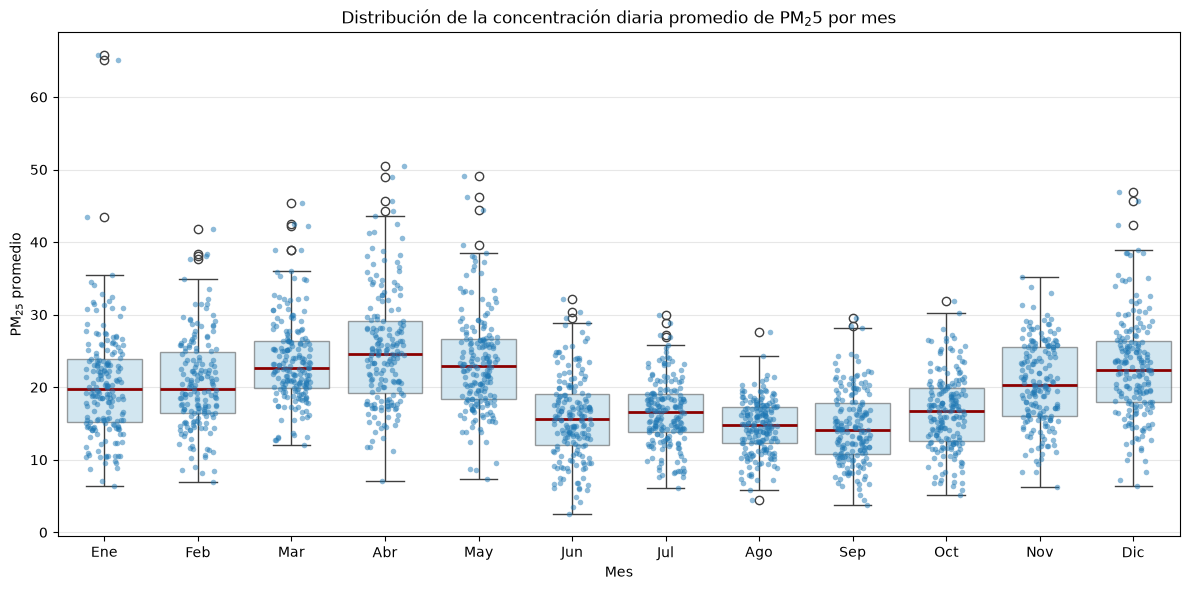

In [22]:
import seaborn as sns

fig,ax= plt.subplots(figsize=(12,6))

sns.boxplot(
    data=pm25,
    x="mes_nombre",
    y="PM25_promedio",
    order=orden_meses,
    ax=ax,
    boxprops=dict(alpha=0.5,facecolor="#a6cee3"),
    medianprops=dict(color="darkred",linewidth=2)
    )

sns.stripplot(
    data=pm25,
    x="mes_nombre",
    y="PM25_promedio",
    order=orden_meses,
    ax=ax,
    color="#1f78b4",
    alpha=0.5,
    jitter=0.2,
    size=4
)

ax.set_title("Distribución de la concentración diaria promedio de PM$_25$ por mes")
ax.set_xlabel("Mes")
ax.set_ylabel("PM$_{25}$ promedio")
ax.grid(axis="y",alpha=0.3)

plt.tight_layout()
plt.show()

El gráfico anterior combina boxplots y puntos diarios para mostrar la distribución mensual de PM$_{25}$. Las medianas y los IQR indican posible patrón estacional, existen meses con medianas y cajas más grandes. Medianas altas indica concentraciones más elevadas por mes. La caja ancha (IQR grande) indica alta variabilidad de dentro de ese mes. Muchos outliers indican episodios agudos (pueden deberse a incendios, contingencias, eventos puntuales, etc.). En cambio cuando los puntos estan más cerca de la mediana (ejem. junio, julio) indican condiciones más estables.

### Boxplots con histogramas
Visión de los histogramas junto cajas boxplots por mes.

In [23]:
orden_meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
 # min() devuelve el valor mínimo y max() el máximo.
global_min= pm25["PM25_promedio"].min()
global_max= pm25["PM25_promedio"].max()
bins_shared=np.linspace(global_min,global_max,20)   # # np.linspace(a, b, n) genera n valores igualmente espaciados entre a y b


In [24]:
pm25.head(2)

,fecha,PM25_promedio,anio,mes,dia,fecha_calendario,mes_nombre
0,2020-01-01,31.281250,2020,1,1,2000-01-01,Ene
1,2020-01-02,6.357639,2020,1,2,2000-01-02,Ene


C:\Users\mnzaa\AppData\Local\Temp\ipykernel_312\829163913.py:31: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax_box.boxplot(
C:\Users\mnzaa\AppData\Local\Temp\ipykernel_312\829163913.py:31: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax_box.boxplot(
C:\Users\mnzaa\AppData\Local\Temp\ipykernel_312\829163913.py:31: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax_box.boxplot(
C:\Users\mnzaa\AppData\Local\Temp\ipykernel_312\829163913.py:31: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax_box.boxplot(
C:\Users\mnzaa\AppData\Local\Temp\ipyker

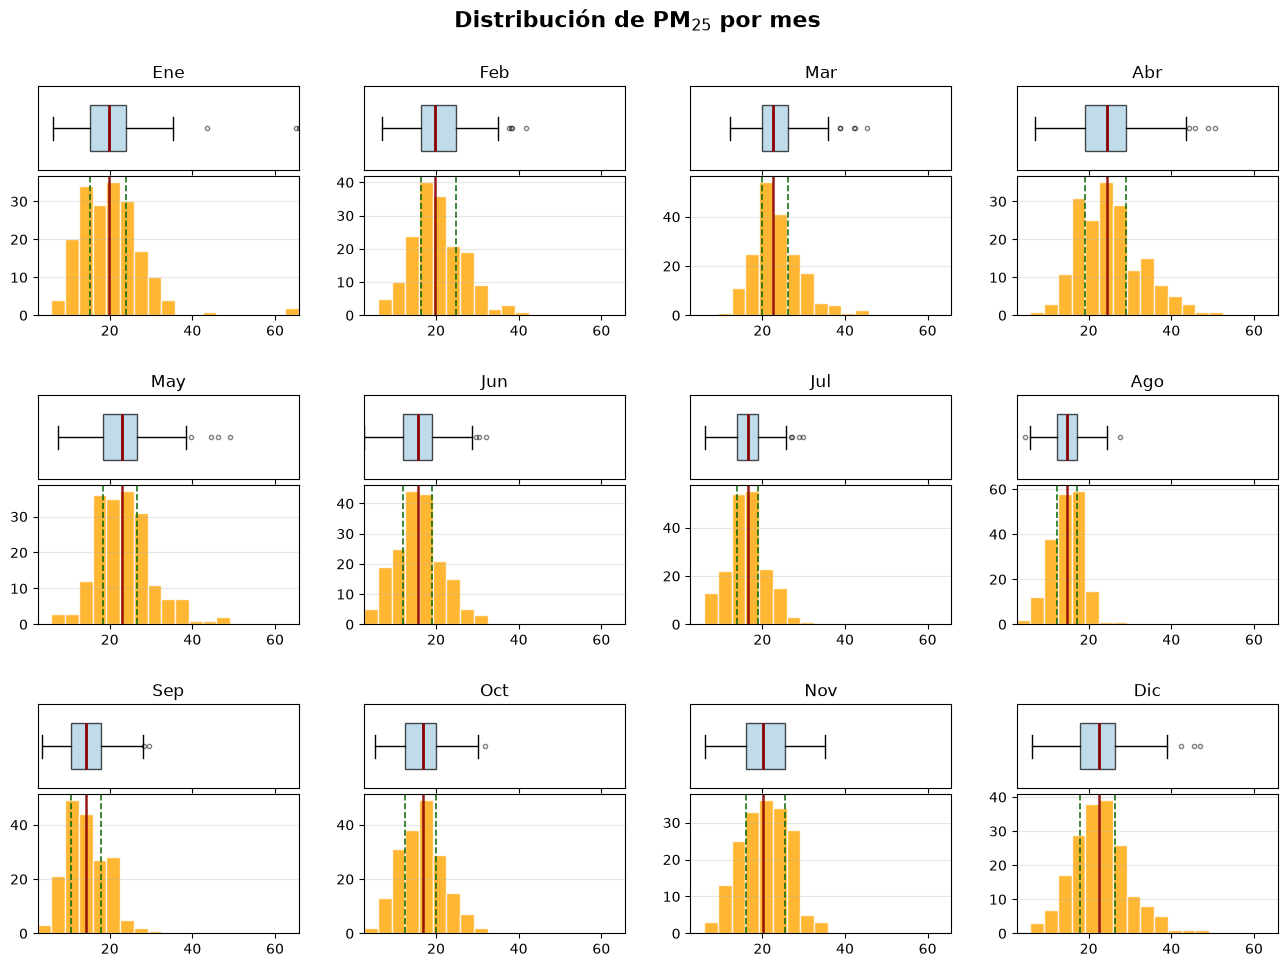

In [25]:
# Figura y cuadrícula principal
fig=plt.figure(figsize=(16,11))
gs_master= fig.add_gridspec(3,4,hspace=0.35,wspace=0.25) # gridspec(3,4) divide en 12 espacios (3 filas × 4 columnas), uno por mes.

first_ax_box=None


for i, mes in enumerate(orden_meses):
    row = i // 4
    col = i % 4
    
    gs_sub = gs_master[row, col].subgridspec(2, 1, height_ratios=[1.5, 2.5], hspace=0.05)
    
    if i == 0:
        ax_box = fig.add_subplot(gs_sub[0])
        ax_hist = fig.add_subplot(gs_sub[1], sharex=ax_box)
        first_ax_box = ax_box
    else:
        ax_box = fig.add_subplot(gs_sub[0], sharex=first_ax_box)
        ax_hist = fig.add_subplot(gs_sub[1], sharex=first_ax_box)


    # Datos y estadísticos
    subset = pm25.loc[pm25["mes_nombre"] == mes, "PM25_promedio"]  # Se filtran los datos de ozono para ese mes.
    # Se calculan mediana y cuartiles.
    mediana_val = subset.median()
    q1_val = subset.quantile(0.25)
    q3_val = subset.quantile(0.75)

    # Dibuja el boxplot horizontal. 
    ax_box.boxplot(
        subset, 
        vert=False, 
        patch_artist=True, 
        widths=0.55,
        boxprops=dict(facecolor="#a6cee3", alpha=0.7),
        medianprops=dict(color="darkred", linewidth=2),
        flierprops=dict(marker='o', markersize=3, alpha=0.5)
    )
    ax_box.set(yticks=[], title=mes)
    ax_box.tick_params(labelbottom=False)

    # Se dibuja el histograma con los bins compartidos.
    ax_hist.hist(subset, bins=bins_shared, color="orange", edgecolor="white", alpha=0.8)
    # Se añaden líneas verticales para cuartiles y mediana.
    ax_hist.axvline(q1_val, color="darkgreen", linestyle="--", linewidth=1.2, alpha=0.9)
    ax_hist.axvline(q3_val, color="darkgreen", linestyle="--", linewidth=1.2, alpha=0.9)
    ax_hist.axvline(mediana_val, color="darkred", linestyle="-", linewidth=1.8, alpha=0.9)
    
    ax_hist.grid(axis="y", alpha=0.3)
    
    ax_box.set_xlim(global_min, global_max)
    ax_hist.set_xlim(global_min, global_max)

fig.suptitle("Distribución de PM$_{25}$ por mes", fontsize=16, fontweight='bold', y=0.95)
plt.show()

## Descomposición STL
La serie temporal se tratará como la aditivad de componentes

$$
Y_t=
T_t
+
S_t
+
R_t,
$$

donde:

- $T_t$ es la tendencia;
- $S_t$ es la componente estacional;
- $R_t$ es el residuo o componente irregular.

La clase **STL (Seasonal-Trend decomposition using Loess)** es una herramienta de la librería `statsmodels` que permite descomponer una serie temporal en tres componentes principales:

1. **Tendencia (Trend):** la evolución a largo plazo de la serie.
2. **Estacionalidad (Seasonal):** patrones repetitivos en intervalos regulares (por ejemplo, variaciones mensuales o anuales).
3. **Residuo (Residual):** la parte no explicada por la tendencia ni la estacionalidad, que incluye ruido y variaciones irregulares.

##### Características principales
- Utiliza **LOESS (Local Regression Smoothing)** para ajustar la tendencia y la estacionalidad de manera flexible.
- Es más robusto que métodos clásicos como `seasonal_decompose`, ya que permite manejar mejor series con ruido o con estacionalidad cambiante.
- Permite ajustar parámetros como el periodo estacional y el grado de suavizado.

##### Utilidad
- Facilita el análisis de series temporales para identificar patrones ocultos.
- Es útil en campos como economía, meteorología, contaminación ambiental, ventas y cualquier contexto donde los datos tengan ciclos y tendencias.
- Ayuda a preparar datos para modelos predictivos, eliminando la estacionalidad o la tendencia antes de aplicar técnicas de pronóstico.

**STL es una técnica avanzada para separar y entender los componentes de una serie temporal**, lo que mejora la interpretación y el análisis de los datos.

In [26]:
pm25.head(2)

,fecha,PM25_promedio,anio,mes,dia,fecha_calendario,mes_nombre
0,2020-01-01,31.281250,2020,1,1,2000-01-01,Ene
1,2020-01-02,6.357639,2020,1,2,2000-01-02,Ene


In [27]:
from statsmodels.tsa.seasonal import STL

# Vamos a hacer índicese temporales. Columna "fecha" como índice. Selecciona "PM25_promedio" ajustando frecuencia diaria ("D")

serie_pm25= pm25.set_index("fecha")["PM25_promedio"].asfreq("D")
serie_pm25

fecha
2020-01-01    31.281250
2020-01-02     6.357639
2020-01-03    10.484375
2020-01-04    30.875000
2020-01-05    21.437500
                ...    
2025-12-27    19.552083
2025-12-28    21.864583
2025-12-29    18.614583
2025-12-30    14.864583
2025-12-31    23.414187
Freq: D, Name: PM25_promedio, Length: 2192, dtype: float64

### SLT Seasonal-Trend Decomposition Procedure Based on Loess
**Artículo**: Cleveland, R. B., Cleveland, W. S., McRae, J. E., & Terpenning, I. (1990).
STL: A Seasonal-Trend Decomposition Procedure Based on Loess. Journal of Official Statistics, 6(1), 3–73.

`STL` Aplica la técnica de Seasonal-Trend decomposition using Loess como herramienta de la librería `statsmodels` que descompone una serie temporal en tres componentes:
1. **Tendencia (Trend):** la evolución a largo plazo de la serie.
2. **Estacionalidad (Seasonal):** patrones repetitivos en intervalos regulares (por ejemplo, variaciones mensuales o anuales).
3. **Residuo (Residual):** la parte no explicada por la tendencia ni la estacionalidad, que incluye ruido y variaciones irregulares.


La descomposición STL ayuda a entender mejor cómo se comporta la serie a lo largo del tiempo, distinguiendo entre lo que es tendencia, lo que es estacionalidad y lo que es ruido.

##### Características principales
- Utiliza **LOESS (Local Regression Smoothing)** para ajustar la tendencia y la estacionalidad de manera flexible.
- Es más robusto que métodos clásicos como `seasonal_decompose`, ya que permite manejar mejor series con ruido o con estacionalidad cambiante.
- Permite ajustar parámetros como el periodo estacional y el grado de suavizado.


El paper  detalla los aspectos técnicos y matemáticos del algoritmo. Explica la estructura de loops internos (ajuste de tendencia y estacionalidad con LOESS) y loops externos (robustez contra outliers). 
Supone modelo aditivo:
$$y_t= T_t + S_t + R_t$$
Para tendencia, estacionalidad y residuo.
#### `robust=True`

Parámetro robust=True está en la librería statsmodels de Python, aplican ponderaciones robustas para reducir la influencia de outliers.

El comando `robust=True` activa un loop externo de robustez dentro del algoritmo STL.  Este loop aplica un esquema de ponderación iterativa sobre los residuos para reducir la influencia de valores atípicos:

##### Cálculo de residuos iniciales
Se descompone la serie en tendencia, estacionalidad  y residuo: $y_t= T_t + S_t + R_t$
##### Asignación de pesos robustos
Cada observación tiene un peso $w_t$  en función del residuo $R_t$. Se usa la función de Tukey.

##### Reajuste de pesos 
Los valores extremos reciben pesos cercanos a cero, reduciendo su impacto en el ajuste de tendencia y estacionalidad. El proceso se repite varias veces hasta estabilizar los componentes.


Se evitan picos anómalos que distorsionen la tendencia  o el patrón estacional. Produce una descomposición más estable y confiable centrada en el comportamiento general de la serie. Especialmente útil en datos ambientales financieros o sociales donde los outliers son frecuentes.

### Descomposición STL
`stl.fit()` aplica el algoritmo de Seasonal-Trend decomposition using Loess a la serie. Lo que resulta es un objeto de tipo `STLResult` que contiene las tres componenetes principales:
- `resultado_stl.trend` Tendencia a largo plazo
- `resultado_stl.trend` Patron estacional
- `resultado_stl.resid` Residuo o ruido

Podemos acceder a cada componente. Es útil para analizar cómo se comporta la serie, separar patrones y preparar datos para pronósticos. En resumen: `stl.fit() ` es el paso que ejecuta la descomposición y devuelve el objeto con los componentes listos para inspección o visualización. Se puede graficar los resultados con `resultado_stl.plot()`.

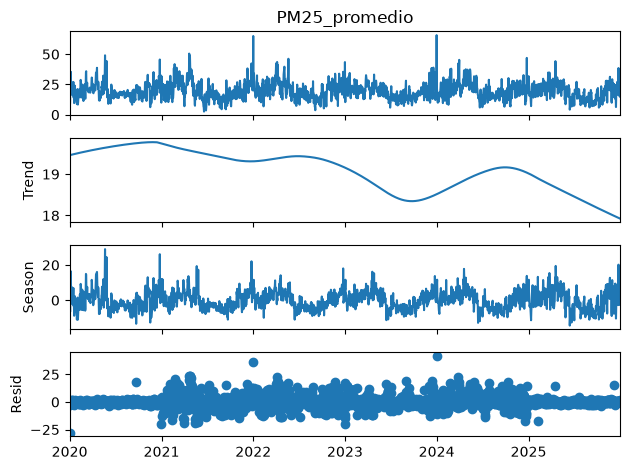

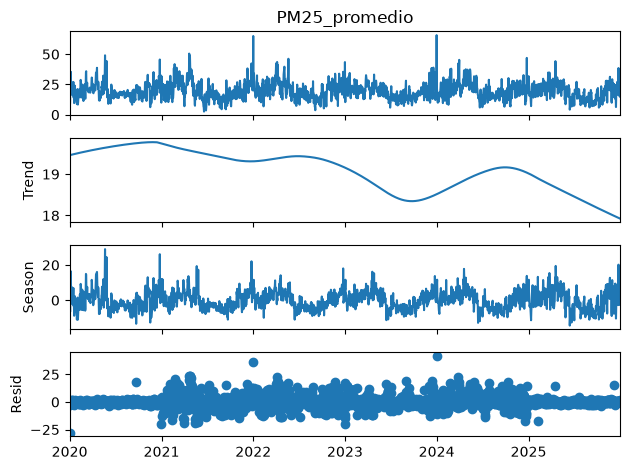

In [28]:
# Descomposición STL
stl= STL(
    serie_pm25,
    period=365,  # (ciclo anual).
    robust=True  # # Hace que la descomposición sea menos sensible a valores atípicos, evitando que afecten demasiado la tendencia o la estacionalidad.
)

# Se ejecuta la descomposición STL sobre la serie con los parámetros: period=365, robust=True
resultado_stl= stl.fit()
resultado_stl.plot()

### Componentes

In [29]:
# Guardamos las componentes
tendencia= resultado_stl.trend
estacional= resultado_stl.seasonal
residuo= resultado_stl.resid

### Visualización


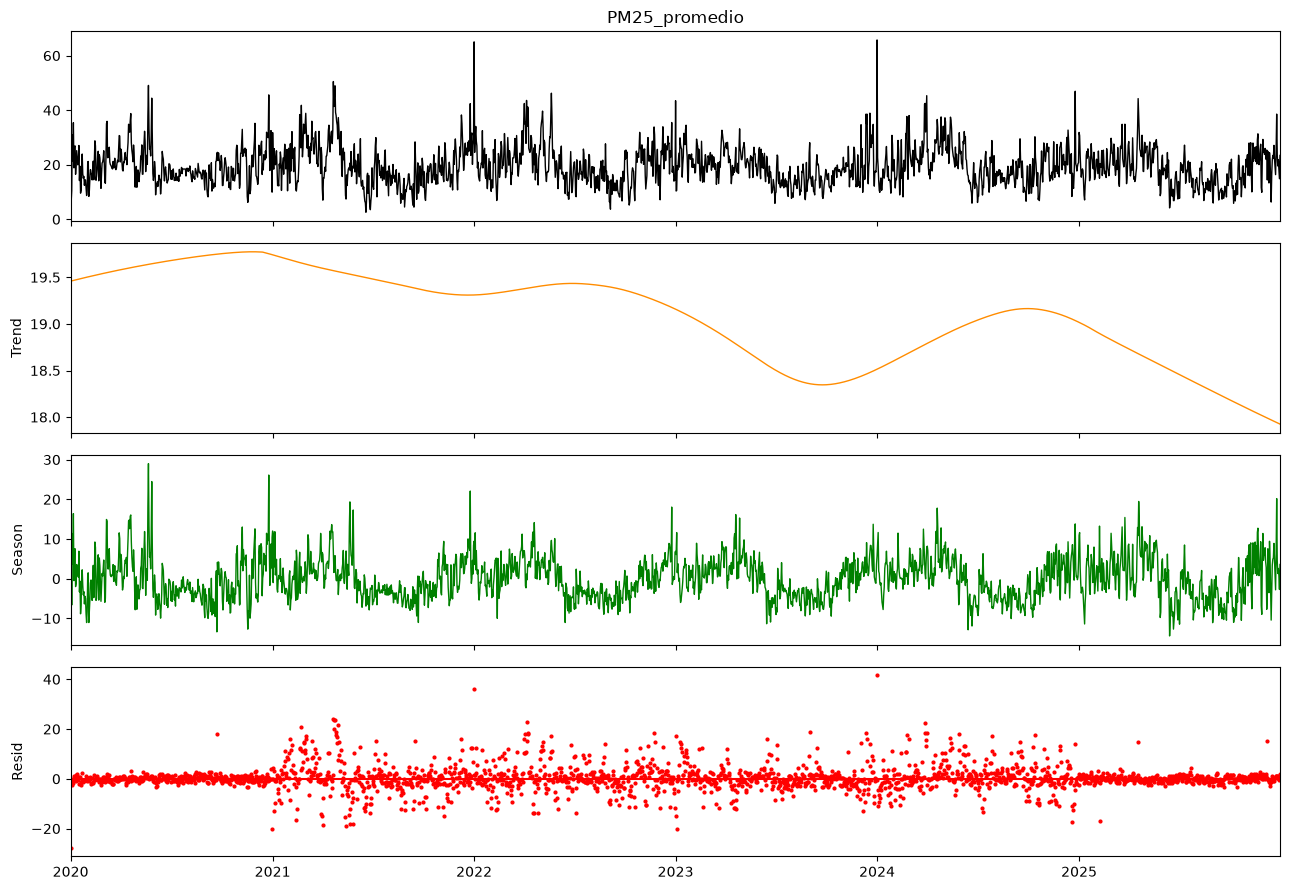

In [30]:

fig=resultado_stl.plot()
fig.set_size_inches(13,9)
# Lista de colores que se usarán para cada subgráfico
colores=["black","darkorange","green","red"]

# fig.axes lista con los ejes (Axes) de la figura, uno por cada subgráfico (serie original, tendencia, estacionalidad, residuo).
# colores es la lista de colores definida
# zip() combina ambas listas en pares: el primer eje con el primer color, el segundo eje con el segundo color, etc.
for i,(ax,color) in enumerate(zip(fig.axes,colores)):
    for line in ax.get_lines():
        line.set_color(color)

        if i==3:
            line.set_markersize(2.0)  # el cuarto subgráfico → el residuo), se ajusta el tamaño de los marcadores a 2.0.
        else:
            line.set_linewidth(1.0)  # En los demás (i=0,1,2), se ajusta el grosor de la línea a 1.0.

plt.tight_layout()

plt.show()

In [31]:
# Ejemplo del for
for i,j in enumerate(zip(fig.axes,colores)):
    print(i,j)

0 (<Axes: title={'center': 'PM25_promedio'}>, 'black')
1 (<Axes: ylabel='Trend'>, 'darkorange')
2 (<Axes: ylabel='Season'>, 'green')
3 (<Axes: ylabel='Resid'>, 'red')


La descomposición STL permite escribir la serie como: $Y_t=T_t+S_t+R_t$. Obtenemos una separación clara entre cambios de largo plazo, ciclo anual repetitivo y variabilidad no explicada. 
#### Serie
Se observa la variabilidad dia a dia, referencia.
#### Tendencia
$T_t$  Representa la evolución de largo plazo de las concentraciones después de filtrar la estacionalidad y el ruido.
- Muestra subidas o bajadas sostenidas, eso puede deberse a cambios en las emisiones o en factores meteorológicos o estructurales.
- `robust=True` hace que la estimación de la tendencia sea menos sensible a valores atípicos. Las variaciones observadas en la curva de tendencia  son más confiables para inferir cambios reales en el sistema.
#### Estacionalidad

La componente $S_t$ presenta un patrón que se repite aproximadamente cada año.

- La magnitud y la forma de la componente estacional permite identificar meses críticos.
- Se captura el patrón repetitivo anual (period=365). Un pico estacional en ciertos meses puedo indicar fenómenos fotoquímicos, metereológicos recurrentes o fuentes estacionales (calefacción, incendios, etc).

#### Residuo
$R_t$ es la variabilidad no explicada por la tendencia ni estacionalidad: ruido, eventos puntuales, errores de medición, efectos no periódicos.
- La presencia de patrones en los residuos (autocorrelación, heteroscedasticidad, clusters de outliers) indica que el modelo STL no captura toda la estructura temporal y que conviene modelar los residuos para pronóstico o inferencia.


### Recomendaciones estadísticas
Pruebas y métricas cuantitativas.
#### Proporción de varianza
Calcular Var(trend), Var(Seasonal), Var(residual) reportar porcentajes relativos respecto a Var(observada). Esto cuantifica cuánto explica cada componente.
#### Significancia de la tendencia.
Pruebas de tendencia como ***Mann-Kendall* o test **KPSS** para verificar la tendencia detectada es estadísticamente significativa y si la serie es estacionaria 
#### Validez de la estacionalidad
Comparar la amplitud estacional entre años y usar análisis de varianza estacional o pruebas de homogeneidad para ver si la estacionalidad es estable en el tiempo.
#### Diagnóstico de residuos
- Autocorrelación con ACF y prueba de Ljung–Box para detectar dependencia temporal.
- Heteroscedasticidad con pruebas como Breusch–Pagan o inspección de la varianza condicional.
- Normalidad de residuos con Shapiro–Wilk o QQ plot si se requiere inferencia paramétrica.
- Identificar y cuantificar outliers residuales y su relación con eventos externos (incendios, contingencias).


#### Si la tendencia es significativa
Investigar causas estructurales: cambios en emisiones, políticas, actividad económica o red de monitoreo. Considerar modelos con covariables exógenas (meteorología, incendios, tráfico).
#### Si la estacionalidad es fuerte y estable
Modelos de pronóstico deben incorporar componente estacional explícito (SARIMA, ETS, Prophet, modelos de regresión con términos estacionales).
#### Si los residuos muestran autocorrelación o heteroscedasticidad
Modelar residuos con procesos ARIMA o modelos GARCH según corresponda; para pronóstico, usar modelos híbridos que combinen descomposición y modelado de residuos.
#### Eventos extremos
Analizar outliers residuales como eventos de interés epidemiológico o de gestión ambiental; evaluar su frecuencia y asociación con variables externas.


#### Recomendaciones prácticas y pasos siguientes

**PARAFRASEAR**
- Cuantificar varianzas y reportar porcentajes de varianza explicada por tendencia y estacionalidad.

- Realizar pruebas: Mann–Kendall o KPSS para tendencia; Ljung–Box para residuos; pruebas de homogeneidad estacional.

- Explorar covariables: incorporar temperatura, viento, precipitación, incendios y actividad vehicular para explicar la tendencia y reducir residuos.

- Modelado para pronóstico: comparar enfoques (STL + ARIMA sobre residuos, SARIMA, Prophet) usando validación temporal y métricas fuera de muestra como RMSE y MAE.

- Análisis de impacto: si la tendencia es ascendente o los picos aumentan, estimar carga de enfermedad atribuible y priorizar intervenciones en meses críticos.

## Cuantificación de la relevancia de las componentes.

Para una serie descompuesta se puede cuantificar la dominancia de la tendencia y la estacionalidad.

### Fuerza de la tendencia $F_T$
Variación del residuo respecto a la variabilidad de la serie sin la componente estacional. Mide la relevancia de la tendencia.
$$F_t = \max \left( 0, 1-\frac{\text{Var}(R_t)}{ \text{Var}(T_t + R_t) } \right) $$

Si el cociente $\frac{\text{Var}(R_t) }{ \text{Var}(T_t + R_t)}$  es pequeño $F_T$ es cercano a 1.


### Fuerza de estacionalidad $F_S$
Mide la relevancia del patrón estacional frente al ruido.
$$F_S = \max\left(0, 1 - \frac{\text{Var}(R_t)}{\text{Var}(S_t + R_t)}\right)$$


### Interpretación
- Valores cercanos a 1 indican que la componente es *fuerte*, significativa respecto al residuo.
- Valores cercanos a 0 indican que la componente es *débil*.

### Varianza `np.var() `
Devuelve la varianza de los elementos del array, una medida de la dispersión de un distribución. 
$$\text{Var}(X)=\frac{1}{N-1} \sum_{i=1}^N(x_i-\bar{x})$$ 

`ddof` es Delta Degrees of Freedom
- Por defecto `ddof=0` calcula la varianza poblacional (divide entre N).
- `ddof=1` Divide entre $N-1$, estimador insesgado


In [32]:
var_residuo = np.var(residuo, ddof=1)
var_residuo

np.float64(26.92655479978606)

In [33]:
# Fuerza de la tendencia y de la estacionalidad
fuerza_tendencia = max(0, 1- var_residuo/ np.var(tendencia+residuo, ddof=1))

fuerza_estacional= max(0,1- var_residuo/ np.var(estacional+residuo, ddof=1))

print("Fuerza de la tendencia: ")
print(f"{fuerza_tendencia:.3f}")

print("\n Fuerza de la estacionalidad: ")
print(f"{fuerza_estacional:.3f}")

Fuerza de la tendencia: 
0.013

 Fuerza de la estacionalidad: 
0.458


La serie presenta una tendencia a largo plazo débil pero una componente estacional importante.
- **Fuerza de la tendencia = 0.013**  1.3 % (aprox.) de la variabilidad explicada por la tendencia.
- **Fuerza de la estacionalidad = 0.458** 45.8 % (aprox.) de la variabilidad explicada por la estacionalidad.

Tomando como referencia la siguiente regla práctica
- **fuerza > 0.5** fuerza alta. 
- **fuerza 0.25–0.5** fuerza moderada.
- **fuerza < 0.25** fuerza débil.

Así, 0.458 es moderada-alta, mientras que 0.013 es insignificante.

#### Tendencia prácticamente nula
Tras separar estacionalidad y ruido, la componente a largo plazo aporta poco a la varianza total. No hay señal de cambio sostenido de los niveles de PM$_{25}$ que explique la variación diaria.

#### Estacionalidad dominante
Una fuerza estacional de 0.458 indica que casi la mitad de la varianza se explica por el ciclo estacional anual. La estacionalidad más importante para describir la variación diaria de PM$_{25}$.

La estacionalidad concentra la mayor parte de la variabilidad, la carga de exposición y los picos de riesgo serán previsibles por mes/estación. Los modelos deberán incorporar explícimente la estacionalidad. La tendencia al ser muy débil, modelos complejos para capturar cambios de largo plazo aportarán poco a la precisión de corto/medio plazo.


### Resumen de las componentes STL


In [34]:
resumen_stl= pd.DataFrame({
    "observada":serie_pm25,
    "tendencia":tendencia,
    "estacional":estacional,
    "residuo":residuo
                           
})

resumen_stl.describe().round(2)

,observada,tendencia,estacional,residuo
count,2192.00,2192.00,2192.00,2192.00
mean,19.51,19.09,-0.02,0.45
std,7.08,0.49,5.30,5.19
min,2.58,17.93,-14.40,-27.70
25%,14.60,18.69,-3.78,-1.33
50%,18.73,19.16,-0.45,0.03
75%,23.67,19.47,3.38,1.65
max,65.75,19.77,28.99,41.54


#### Serie observada
La concentración media diaria está cerca de 20$\frac{\micro g}{m^3}$, pero existen episodios extremos (máx ≈ 66) que elevan la variabilidad.

#### Tendencia casi nula
media = 19.09, std = 0.49, min = 17.93, max = 19.77. Varía menos de dos unidades en todo el periodo. No hay un cambio marcado de largo plazo. La varianza de la tendencia es muy pequeña frente a la varianza total; la serie no muestra un aumento o disminución sostenida relevante en el periodo analizado. Comparar con  (Mann–Kendall corregido).

#### Estacionalidad dominante
Estacionalidad tiene amplitud notable,  lo que indica un ciclo anual fuerte con meses por encima y por debajo del promedio. La desviación estándar de la componente estacional (5.30) es del mismo orden que la de los residuos (5.19) y representa una fracción importante de la variabilidad observada. 
#### Residuos
Los residuos alcanzan valores extremos (hasta +41.5 y −27.7). Hay episodios de contaminación aguda más intensos que los descensos.


### Días con residuos más extremos

Tabla de los 10 días en la que la serie observada y la parte explicada por tendencia + estacionalidad fue la más extrema en magnitud. Estos valores son posibles candidatos de eventos atípicos

In [35]:
residuos_extremos= (
    
    resumen_stl   # DataFrame que contiene las columnas "observada", "tendencia", "estacional" y "residuo" para cada fecha de la serie.
    .assign(residuo_abs=lambda x: x["residuo"].abs()) # nueva columna llamada residuo_abs que contiene el valor absoluto de residuo.
    .sort_values("residuo_abs",ascending=False)  
    .head(10)
)

print("\nDías con mayor residuo absoluto: ")
residuos_extremos.round(2).head(10)


Días con mayor residuo absoluto: 


,observada,tendencia,estacional,residuo,residuo_abs
fecha,,,,,
2024-01-01,65.75,18.51,5.70,41.54,41.54
2022-01-01,65.04,19.31,9.46,36.27,36.27
2020-01-02,6.36,19.46,14.60,-27.70,27.70
2021-04-21,50.50,19.57,7.04,23.89,23.89
2021-04-23,45.69,19.57,2.40,23.72,23.72
2021-04-24,48.94,19.57,5.82,23.55,23.55
2022-04-06,43.58,19.38,1.16,23.04,23.04
2024-03-28,42.49,18.78,1.30,22.41,22.41
2021-04-30,37.29,19.56,-3.98,21.71,21.71


In [36]:
top_positivos = resumen_stl.nlargest(10, "residuo")
top_negativos = resumen_stl.nsmallest(10, "residuo")


In [37]:
top_positivos.round(2)

,observada,tendencia,estacional,residuo
fecha,,,,
2024-01-01,65.75,18.51,5.70,41.54
2022-01-01,65.04,19.31,9.46,36.27
2021-04-21,50.50,19.57,7.04,23.89
2021-04-23,45.69,19.57,2.40,23.72
2021-04-24,48.94,19.57,5.82,23.55
2022-04-06,43.58,19.38,1.16,23.04
2024-03-28,42.49,18.78,1.30,22.41
2021-04-30,37.29,19.56,-3.98,21.71
2021-02-22,41.79,19.65,1.47,20.67


In [38]:
top_negativos.round(2)

,observada,tendencia,estacional,residuo
fecha,,,,
2020-01-02,6.36,19.46,14.60,-27.70
2020-12-31,9.96,19.74,10.45,-20.24
2023-01-03,10.57,19.15,11.63,-20.21
2021-05-14,7.42,19.54,7.00,-19.13
2021-04-02,7.02,19.60,6.11,-18.69
2021-05-21,20.60,19.53,19.35,-18.28
2021-05-27,18.77,19.53,17.32,-18.07
2024-12-19,8.38,19.05,6.82,-17.50
2025-02-07,15.04,18.90,13.26,-17.12


## Autocorrelación: ACF Y PACF

La función de autocorrelación **ACF** mide la correlación de $Y_t$
y sus $k$ rezagos:

$$
\rho(k)
=\operatorname{Corr}
\left(
Y_t,Y_{t-k}
\right).
$$

La función de autocorrelación parcial **PACF** mide la relación entre  $Y_t$ y $Y_{t-k}$ después de eliminar el efecto lineal de los rezagos intermedios.

- *ACF* describe dependencia total con valores pasados.
- *PACF* contribución directa de cada rezago.






### Función de Autocorrelación ACF

Para los primeros 60 días se calcula y se grafica la **Función de Autocorrelación ACF** de la serie PM$_{25}$. Muestra que tan correlacionada está la serie con sus propios valores en días anteriores.

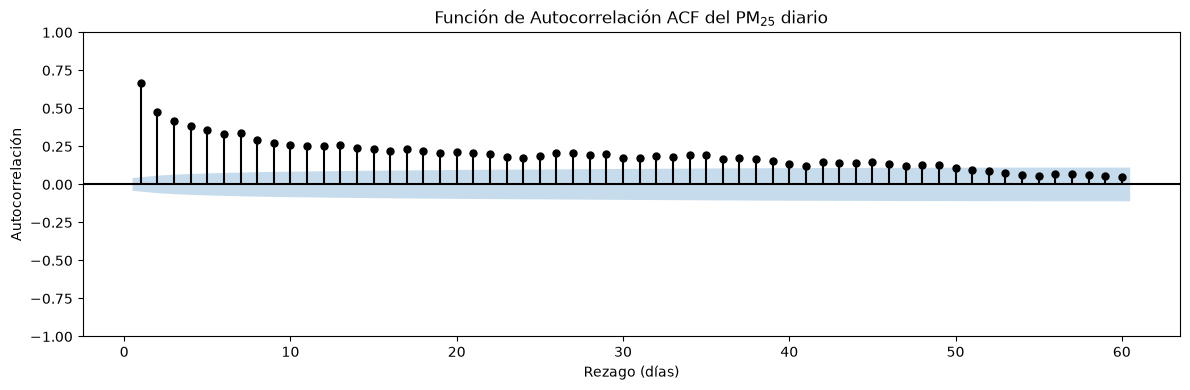

In [39]:
from statsmodels.graphics.tsaplots import (plot_acf,plot_pacf)
# plot_acf grafica la función de autocorrelación

fig, ax= plt.subplots(figsize=(12,4))

plot_acf(
    serie_pm25,
    lags=60, # 60 rezagos (días) frecuencia temporal "D"
    zero=False, # No muestra rezago 0
    ax=ax,
    color="black",
    vlines_kwargs={"colors":"black"}
)

ax.set_title("Función de Autocorrelación ACF del PM$_{25}$ diario")

ax.set_xlabel("Rezago (días)")
ax.set_ylabel("Autocorrelación")

plt.tight_layout()
plt.show()

### Función de Autocorrelación Parcial

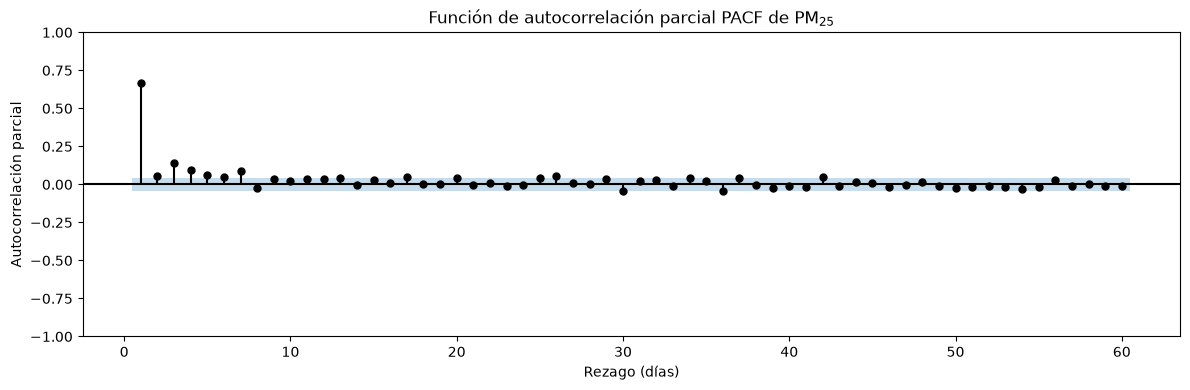

In [40]:
# PACF para los primeros 60 días
# plot_pacf: grafica la función de autocorrelación parcial

fig,ax= plt.subplots(figsize=(12,4))

plot_pacf(
    serie_pm25,
    lags=60,  
    zero=False,
    method="ywm", # Usa el estimador Yule-Walker modificado
    ax=ax,
    color="black",
    vlines_kwargs={"colors":"black"}

)

ax.set_title("Función de autocorrelación parcial PACF de PM$_{25}$")
ax.set_xlabel("Rezago (días)")
ax.set_ylabel("Autocorrelación parcial")

plt.tight_layout()
plt.show()

### Rezagos específicos

In [41]:
# Rezagos específicos

rezagos_interes= [1,2,3,7,14,30,365]
autocorrelaciones=[]

for k in rezagos_interes:
    autocorrelaciones.append({
        "rezago_dias":k,
        "autocorrelacion":serie_pm25.autocorr(lag=k)
    })

autocorrelaciones= pd.DataFrame(autocorrelaciones)

print("Autocorrelaciones en rezagos seleccionados: ")
autocorrelaciones.round(3)

Autocorrelaciones en rezagos seleccionados: 


,rezago_dias,autocorrelacion
0,1,0.669
1,2,0.477
2,3,0.416
3,7,0.338
4,14,0.241
5,30,0.178
6,365,0.318


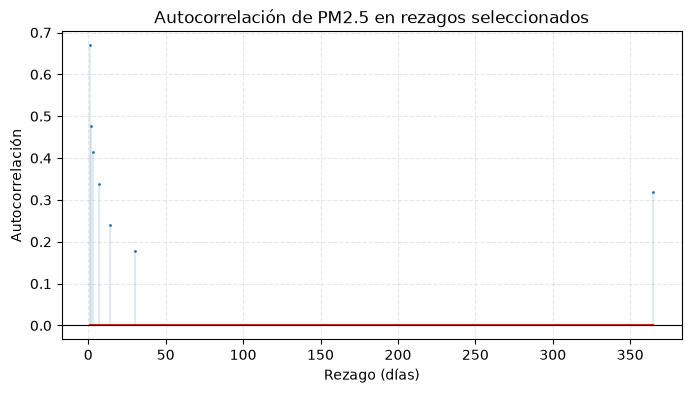

In [42]:
plt.figure(figsize=(8,4))
markerline, stemlines, baseline= plt.stem(
    autocorrelaciones["rezago_dias"],
    autocorrelaciones["autocorrelacion"]
)

plt.setp(stemlines, linewidth=0.2)
plt.setp(markerline, markersize=1)

plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("Rezago (días)")
plt.ylabel("Autocorrelación")
plt.title("Autocorrelación de PM2.5 en rezagos seleccionados")
plt.grid(True, linestyle="--", alpha=0.3)

plt.show()

### Función de Autocorrelación Extendida

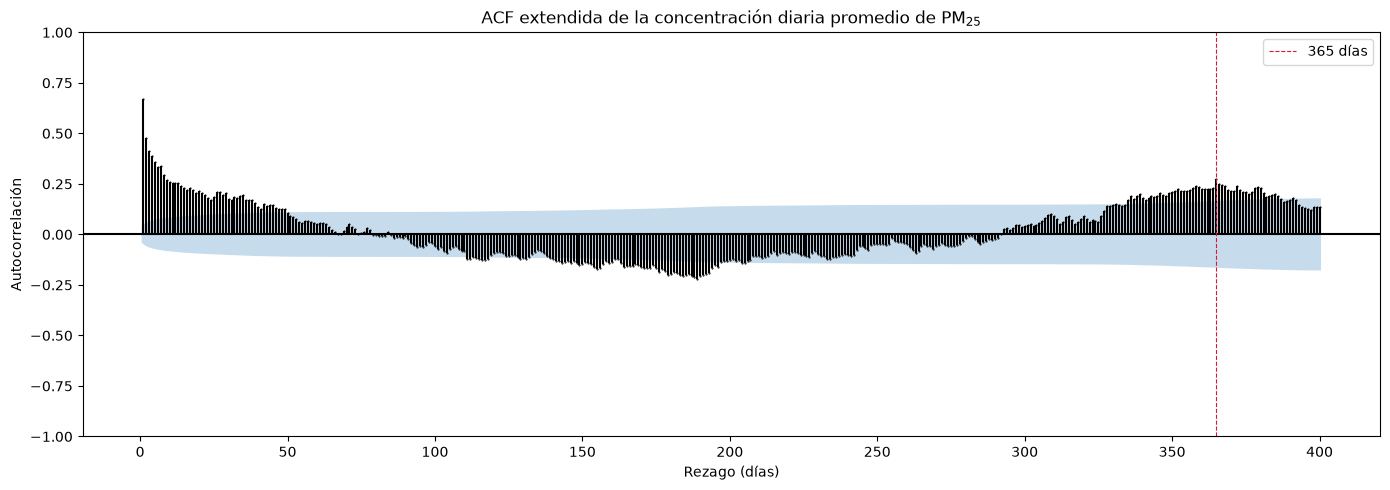

In [43]:
# ACF extendida para observar el ciclo anual

fig,ax= plt.subplots(figsize=(14,5))

# Función de autocorrelación con rezagos de hasta 400 días
plot_acf(
    serie_pm25,
    lags=400,
    zero=False,
    ax=ax,
    color="black",
    vlines_kwargs={"colors":"black"},
    markersize=0.5
)

# Línea vertical discontinua en el rezago 365
ax.axvline(
    365,
    linestyle="--",
    linewidth=0.8,
    label="365 días",
    color="crimson"
)

ax.set_title("ACF extendida de la concentración diaria promedio de PM$_{25}$")
ax.set_xlabel("Rezago (días)")
ax.set_ylabel("Autocorrelación")
ax.legend()
plt.tight_layout()
plt.show()

#### Autocorrelación alrededor del ciclo anual



In [44]:
rezago_anuales = [330, 345, 360, 365, 370, 380, 400]

autocorrelaciones=[]

for k in rezago_anuales:
    valor= serie_pm25.autocorr(lag=k)   # autocorrelación para el rezago k
    autocorrelaciones.append(valor)
    
# Construir tabla
acf_anual= pd.DataFrame({
    "rezago_dias":rezago_anuales,
    "autocorrelaciones":autocorrelaciones
})

acf_anual.round(3)

,rezago_dias,autocorrelaciones
0,330,0.169
1,345,0.219
2,360,0.260
3,365,0.318
4,370,0.247
5,380,0.272
6,400,0.158


#### Interpretación de ACF extendida

## Pruebas ADF y KPSS

La estacionariedad de una serie se evalúa con dos pruebas: ADF (Augmented Dickey-Fuller) y KPSS (Kwiatkowski-Phillips-Schmidt-Shin). La prueba ADF contrasta la hipótesis nula de presencia de raíz nula unitaria contra la alternativa de estacionariedad, mientras que la prueba KPSS plantea como hipótesis nula la estacionariedad de la serie alrededor de una media constante. 

Al usar estas pruebas conjuntamente obtenemos evidencia complementaria del comportamiento estocástico de la serie, reduciendo el riesgo de conclusiones erróneas.

### Prueba ADF Augmented Dickey-Fuller

Usamos la prueba ADF para determinar la presencia de raíz unitaria en la serie que ayuda a entender si la serie es estacionaria o no.

- Hipótesis nula: La serie tiene raíz unitaria (no es estacionaria)
- Hipótesis alternativa: La seria no tiene raíz unitaria (serie estacionaria)


Si se rechaza hipótesis nula, existe evidencia estadística de que la serie no presenta raíz unitaria.
  

In [45]:
from statsmodels.tsa.stattools import adfuller, kpss


In [46]:
# Función ejemplo de la documentación
def adf_prueba(serie_temporal):
    print("\nResultados de la prueba ADF: ")
    dftest= adfuller(serie_temporal, autolag="AIC", result_object=True)
    dfsalida= pd.Series(
        [dftest.statistic,dftest.pvalue,dftest.lags,int(dftest.nobs)],
        index= [
            "Estadístico ADF", "p-value","Número de rezagos","Número de observaciones"
        ]
    )

    for i,j in dftest.critical_values.items():
        dfsalida[f"Valor Crítico ({i})"]=j
    print(dfsalida)

    return dftest.statistic,dftest.pvalue,dftest.lags
# Implementación
adf_stat, adf_pvalue, adf_lags= adf_prueba(serie_pm25)


Resultados de la prueba ADF: 
Estadístico ADF           -7.335541e+00
p-value                    1.099049e-10
Número de rezagos          1.200000e+01
Número de observaciones    2.179000e+03
Valor Crítico (1%)        -3.433355e+00
Valor Crítico (5%)        -2.862867e+00
Valor Crítico (10%)       -2.567477e+00
dtype: float64


#### Prueba de hipótesis

In [47]:
alpha=0.05

print(f"\nInterpretación con α = {alpha}")
print("-"*50)

# ADF
if adf_pvalue< alpha:
    print("ADF: Se rechaza H0. Existe evidencia estadística de que la serie no posee raíz unitaria.")
else:
    print("ADF: No se rechaza H0. No existe evidencia suficiente para descartar la presencia de una raíz unitaria.")



Interpretación con α = 0.05
--------------------------------------------------
ADF: Se rechaza H0. Existe evidencia estadística de que la serie no posee raíz unitaria.


### Prueba Kwiatkowski-Phillips-Schmidt-Shin KPPS 

- Hipótesis nula: El proceso es estacionario alrededor de una constante.
- Hipótesis alternativa: La serie presenta una raíz unitaria (serie no estacionaria)

Si no se rechaza H0, los datos son compatibles con una serie estacionaria alrededor de una media constante.

In [48]:
def kpss_prueba(serie_temporal):
    print("\nResultados de la prueba KPSS: ")
    kpsstest= kpss(serie_temporal, regression="c", nlags="auto", result_object=True)
    kpss_salida= pd.Series(
        [kpsstest.statistic, kpsstest.pvalue, kpsstest.lags], index=["Test Statistic", "p-value", "Lags Used"]
    )

    for i,j in kpsstest.critical_values.items():
        kpss_salida[f"Valores críticos ({i})"]= j
    print(kpss_salida)

    return kpsstest.statistic, kpsstest.pvalue, kpsstest.lags

# Implementación
kpss_stat, kpss_pvalue,kpss_lags=  kpss_prueba(serie_pm25)


Resultados de la prueba KPSS: 
Test Statistic              0.157266
p-value                     0.100000
Lags Used                  25.000000
Valores críticos (10%)      0.347000
Valores críticos (5%)       0.463000
Valores críticos (2.5%)     0.574000
Valores críticos (1%)       0.739000
dtype: float64


C:\Users\mnzaa\AppData\Local\Temp\ipykernel_312\84047497.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpsstest= kpss(serie_temporal, regression="c", nlags="auto", result_object=True)


#### Prueba de hipótesis

In [49]:
alpha=0.05

print(f"\nInterpretación con α = {alpha}")
print("-"*50)

# KPSS
if kpss_pvalue< alpha:
    print( "KPSS: Se rechaza H0. Existe evidencia estadística de que la serie no es estacionaria."
    )
else:
    print("KPSS: No se rechaza H0. Los datos son compatibles con una serie estacionaria."
    )



Interpretación con α = 0.05
--------------------------------------------------
KPSS: No se rechaza H0. Los datos son compatibles con una serie estacionaria.


## Eliminación de la componente estacional

La serie PM$_{25}$ presenta estacionalidad visual y una Fuerza de Estacionalidad de 0.458. La presencia de estacionalidad fuerte puede afectar la interpretación de las pruebas de raíz unitaria. La dependencia temporal inducida por la estacionalidad puede confundirse con una falta de estacionariedad. Aplicamos pruebas **ADF** y **KPSS** a la serie
$$Y_t - S_t = T_t + R_t$$
para evaluar la existencia de una raíz unitaria una vez removido el patrón anual.

In [50]:
# Serie desestacionalizada

serie_desestacionalizada= serie_pm25 - estacional


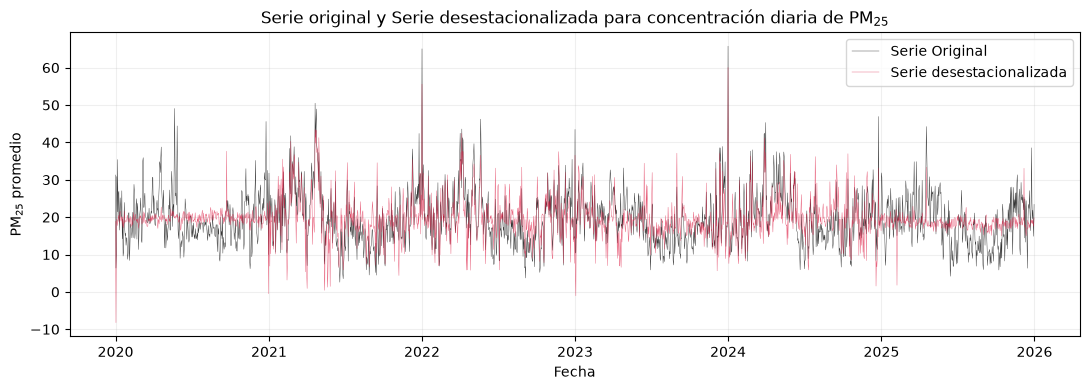

In [51]:

# Comparación gráfica
fig,ax=plt.subplots(figsize=(11,4))

ax.plot(
    serie_pm25.index,
    serie_pm25,
    linewidth=0.3,
    alpha=0.8,
    label="Serie Original",
    color="black"
)

ax.plot(
    serie_desestacionalizada.index,
    serie_desestacionalizada,
    linewidth=0.3,
    alpha=0.7,
    label="Serie desestacionalizada",
    color="crimson"
)

ax.set_title("Serie original y Serie desestacionalizada para concentración diaria de PM$_{25}$")
ax.set_xlabel("Fecha")
ax.set_ylabel("PM$_{25}$ promedio")

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Gráfica de Función de Autocorrelación para serie desestacionalizada

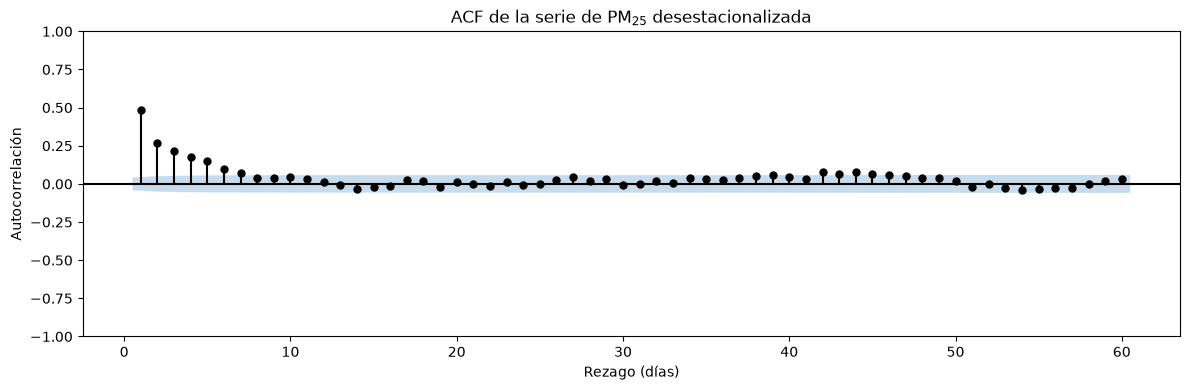

In [52]:
# ACF de la serie desestacionalizada

fig, ax = plt.subplots(figsize=(12, 4))

plot_acf(
    serie_desestacionalizada,
    lags=60,
    zero=False,
    ax=ax,
    color='black',
    vlines_kwargs={'colors': 'black'}
)

ax.set_title("ACF de la serie de PM$_{25}$ desestacionalizada")

ax.set_xlabel("Rezago (días)")
ax.set_ylabel("Autocorrelación")

plt.tight_layout()
plt.show()

In [53]:
# Comparación de autocorrelaciones 
rezagos_comparacion= [1,7,30,365]

comparacion_acf = pd.DataFrame({
    "rezago_dias": rezagos_comparacion,
    "serie_original": [
        serie_pm25.autocorr(lag=k)
        for k in rezagos_comparacion
    ],
    "serie_desestacionalizada": [
        serie_desestacionalizada.autocorr(lag=k)
        for k in rezagos_comparacion
    ]
})

comparacion_acf.round(3)


,rezago_dias,serie_original,serie_desestacionalizada
0,1,0.669,0.483
1,7,0.338,0.075
2,30,0.178,-0.008
3,365,0.318,-0.020


### Pruebas ADF y KPSS para serie desestacionalizada


In [54]:

# ADF sobre la serie desestacionalizada
adf_des_stat, adf_des_pvalue, adf_des_lags= adf_prueba(serie_desestacionalizada)

# KPSS sobre la serie desestacionalizada
kpss_des_stat, kpss_des_pvalue,kpss_des_lags=  kpss_prueba(serie_desestacionalizada)


Resultados de la prueba ADF: 
Estadístico ADF           -1.495716e+01
p-value                    1.255133e-27
Número de rezagos          4.000000e+00
Número de observaciones    2.187000e+03
Valor Crítico (1%)        -3.433344e+00
Valor Crítico (5%)        -2.862862e+00
Valor Crítico (10%)       -2.567474e+00
dtype: float64

Resultados de la prueba KPSS: 
Test Statistic              0.381287
p-value                     0.085221
Lags Used                  21.000000
Valores críticos (10%)      0.347000
Valores críticos (5%)       0.463000
Valores críticos (2.5%)     0.574000
Valores críticos (1%)       0.739000
dtype: float64


#### Prueba de hipótesis


In [55]:
print("\nConclusión conjunta")
print("-"*50)

if adf_des_pvalue < alpha and kpss_des_pvalue > alpha:
    print(
        "La evidencia de ADF y KPSS es consistente con una serie estacionaria."
    )

elif adf_des_pvalue > alpha and kpss_des_pvalue < alpha:
    print(
        "La evidencia de ADF y KPSS es consistente con una serie no estacionaria."
    )

elif adf_des_pvalue < alpha and kpss_des_pvalue < alpha:
    print(
        "Las pruebas producen resultados contradictorios. "
        "La serie podría presentar tendencia determinista, "
        "cambios estructurales, no linealidades o una "
        "estacionariedad incompleta."
    )

else:
    print(
        "Las pruebas son inconclusas. "
        "Se recomienda complementar con análisis gráfico "
        "y otras pruebas de estacionariedad."
    )



Conclusión conjunta
--------------------------------------------------
La evidencia de ADF y KPSS es consistente con una serie estacionaria.


In [56]:
# Comparación

comparacion_estacionariedad = pd.DataFrame({
    "serie": ["Original","Desestacionalizada"],
    "ADF_estadistico": [adf_stat,adf_des_stat],
    "ADF_pvalue": [adf_pvalue,adf_des_pvalue],
    "KPSS_estadistico": [kpss_stat,kpss_des_stat],
    "KPSS_pvalue": [kpss_pvalue,kpss_des_pvalue]
})

comparacion_estacionariedad

,serie,ADF_estadistico,ADF_pvalue,KPSS_estadistico,KPSS_pvalue
0,Original,-7.335541,1.099049e-10,0.157266,0.100000
1,Desestacionalizada,-14.957158,1.255133e-27,0.381287,0.085221


**Estadístico ADF** se vuelve más negativo, esto indica que gran parte de la dependencia temporal detectada provenía del ciclo anual. Es decir, la principal estructura de la serie era la estacionalidad, no una raíz unitaria. La eliminación de la componente estacional fortalece aún más la evidencia de estacionariedad, consistente con **Fuerza de tendencia** = 0.013 y **Fuerza estacional** = 0.458. Estos resultados con consistentes con una serie estacionaria.


$$Y_t  \backsim \text{Estacionaria}$$

## Residuos 
Para verificar si la descomposición STL eliminó adecuadamente la estructura temporal y que el residuo contenga únicamente la parte impredecible de la serie realizamos las pruebas ADF, KPSS y además la prueba Ljung-Box.


In [57]:
# Residuo

residuo= serie_desestacionalizada- tendencia

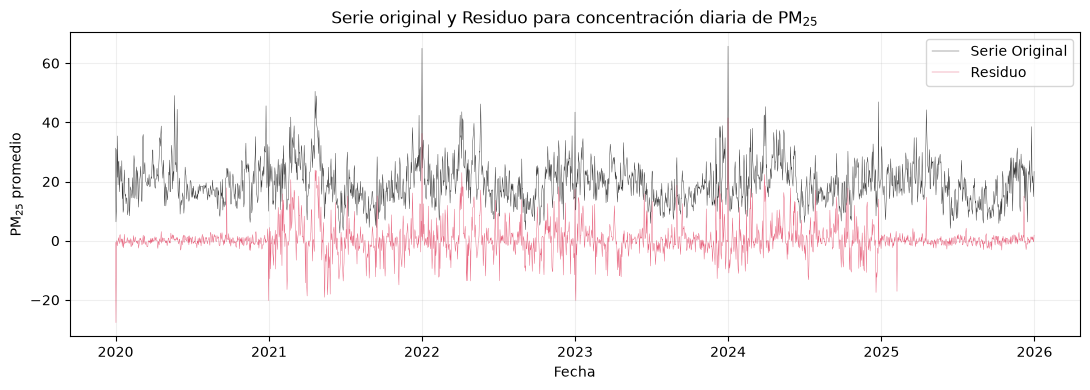

In [58]:
# Comparación gráfica
fig,ax=plt.subplots(figsize=(11,4))

ax.plot(
    serie_pm25.index,
    serie_pm25,
    linewidth=0.3,
    alpha=0.8,
    label="Serie Original",
    color="black"
)

ax.plot(
    residuo.index,
    residuo,
    linewidth=0.3,
    alpha=0.7,
    label="Residuo",
    color="crimson"
)

ax.set_title("Serie original y Residuo para concentración diaria de PM$_{25}$")
ax.set_xlabel("Fecha")
ax.set_ylabel("PM$_{25}$ promedio")

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Gráfica de Función de Autocorrelación para serie desestacionalizada

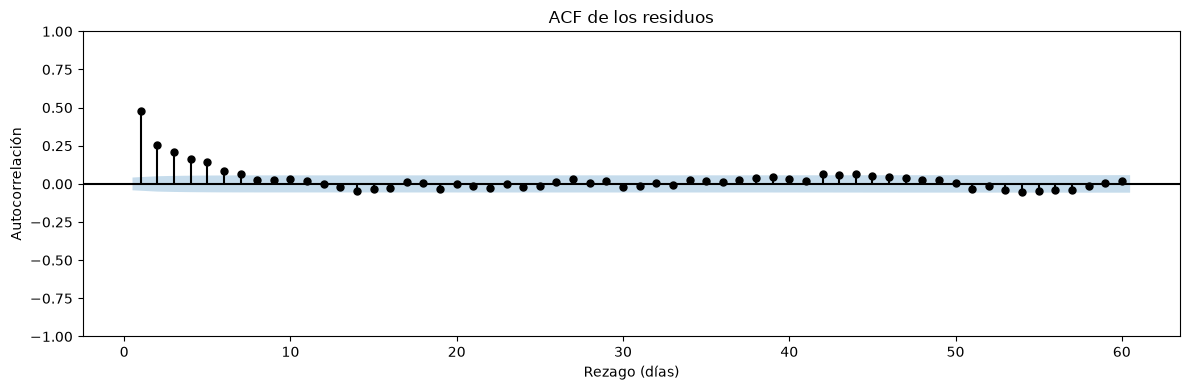

In [59]:
# ACF de los residuos

fig, ax = plt.subplots(figsize=(12, 4))

plot_acf(
    residuo,
    lags=60,
    zero=False,
    ax=ax,
    color='black',
    vlines_kwargs={'colors': 'black'}
)

ax.set_title("ACF de los residuos")

ax.set_xlabel("Rezago (días)")
ax.set_ylabel("Autocorrelación")

plt.tight_layout()
plt.show()

In [60]:
# Comparación de autocorrelaciones 
#rezagos_comparacion= [1,2,3,4,5,6,7,30,365]
rezagos_comparacion= list(range(1, 31))
comparacion_acf = pd.DataFrame({
    "rezago_dias": rezagos_comparacion,
    "serie_original": [
        serie_pm25.autocorr(lag=k)
        for k in rezagos_comparacion
    ],
    "residuos": [
        residuo.autocorr(lag=k)
        for k in rezagos_comparacion
    ]
})

print(comparacion_acf.round(3))


    rezago_dias  serie_original  residuos
0             1           0.669     0.476
1             2           0.477     0.258
2             3           0.416     0.208
3             4           0.388     0.164
4             5           0.359     0.143
5             6           0.333     0.084
6             7           0.338     0.063
7             8           0.295     0.026
8             9           0.272     0.028
9            10           0.260     0.031
10           11           0.257     0.020
11           12           0.256     0.000
12           13           0.258    -0.020
13           14           0.241    -0.049
14           15           0.232    -0.037
15           16           0.222    -0.026
16           17           0.232     0.014
17           18           0.223     0.006
18           19           0.207    -0.031
19           20           0.218    -0.000
20           21           0.207    -0.014
21           22           0.199    -0.025
22           23           0.183   

Sigue existiendo dependencia temporal a corto plazo, para un rezago 7 ( dependencia semanal) la autocorrelación casi desaparece. Para dependencia anual (365) es prácticamente cero. De modo que STL removió correctamente la estacionalidad anual.
$$\rho (365)= 0.318 \rightarrow -0.016$$

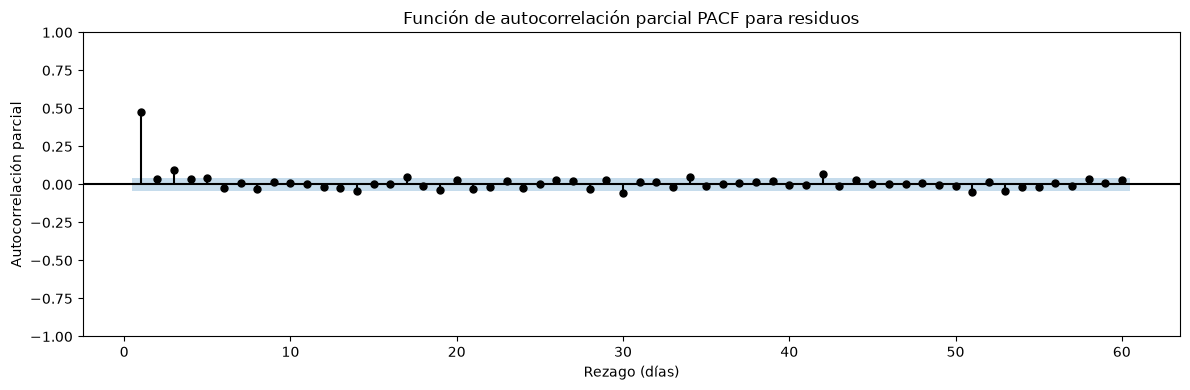

In [65]:
# PACF para los primeros 60 días
# plot_pacf: grafica la función de autocorrelación parcial

fig,ax= plt.subplots(figsize=(12,4))

plot_pacf(
    residuo,
    lags=60,  
    zero=False,
    method="ywm", # Usa el estimador Yule-Walker modificado
    ax=ax,
    color="black",
    vlines_kwargs={"colors":"black"}

)

ax.set_title("Función de autocorrelación parcial PACF para residuos")
ax.set_xlabel("Rezago (días)")
ax.set_ylabel("Autocorrelación parcial")

plt.tight_layout()
plt.show()

### Pruebas ADF y KPSS para residuos


In [66]:
# ADF sobre la serie desestacionalizada
adf_ruido_stat, adf_ruido_pvalue, adf_ruido_lags= adf_prueba(residuo)

# KPSS sobre la serie desestacionalizada
kpss_ruido_stat, kpss_ruido_pvalue,kpss_ruido_lags=  kpss_prueba(residuo)


Resultados de la prueba ADF: 
Estadístico ADF           -1.520563e+01
p-value                    5.748184e-28
Número de rezagos          4.000000e+00
Número de observaciones    2.187000e+03
Valor Crítico (1%)        -3.433344e+00
Valor Crítico (5%)        -2.862862e+00
Valor Crítico (10%)       -2.567474e+00
dtype: float64

Resultados de la prueba KPSS: 
Test Statistic              0.060514
p-value                     0.100000
Lags Used                  21.000000
Valores críticos (10%)      0.347000
Valores críticos (5%)       0.463000
Valores críticos (2.5%)     0.574000
Valores críticos (1%)       0.739000
dtype: float64


C:\Users\mnzaa\AppData\Local\Temp\ipykernel_312\84047497.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpsstest= kpss(serie_temporal, regression="c", nlags="auto", result_object=True)


### Prueba de hipótesis

In [62]:
print("\nConclusión conjunta")
print("-"*50)

if adf_ruido_pvalue < alpha and kpss_ruido_pvalue > alpha:
    print(
        "La evidencia de ADF y KPSS es consistente con una serie estacionaria."
    )

elif adf_ruido_pvalue > alpha and kpss_ruido_pvalue < alpha:
    print(
        "La evidencia de ADF y KPSS es consistente con una serie no estacionaria."
    )

elif adf_ruido_pvalue < alpha and kpss_ruido_pvalue < alpha:
    print(
        "Las pruebas producen resultados contradictorios. "
        "La serie podría presentar tendencia determinista, "
        "cambios estructurales, no linealidades o una "
        "estacionariedad incompleta."
    )

else:
    print(
        "Las pruebas son inconclusas. "
        "Se recomienda complementar con análisis gráfico "
        "y otras pruebas de estacionariedad."
    )



Conclusión conjunta
--------------------------------------------------
La evidencia de ADF y KPSS es consistente con una serie estacionaria.


### Prueba Ljung-Box

Evalua la prueba de hipótesis
- Hipótesis nula: no hay autocorrelación
- Hipótesis alternativa: hay autocorrelación

In [63]:
from statsmodels.stats.diagnostic import acorr_ljungbox

ljung = acorr_ljungbox(
    residuo,
    #residuo.dropna(),
    lags=[1, 7, 14, 30, 60, 90, 180, 365],
    return_df=True
)

print(ljung)

         lb_stat      lb_pvalue
1     497.971880  2.625730e-110
7     862.540316  5.882563e-182
14    874.801152  1.079622e-177
30    889.086317  1.206731e-167
60    978.942582  3.216143e-166
90   1072.121102  7.758674e-168
180  1223.723819  1.362497e-154
365  1594.951110  5.546654e-153


#### Prueba de hipótesis

In [64]:
alpha = 0.05

for lag in ljung.index:

    p = ljung.loc[lag, "lb_pvalue"]

    if p < alpha:
        print(f"Lag {lag}: existe autocorrelación.")
    else:
        print(f"Lag {lag}: compatible con ruido blanco.")

Lag 1: existe autocorrelación.
Lag 7: existe autocorrelación.
Lag 14: existe autocorrelación.
Lag 30: existe autocorrelación.
Lag 60: existe autocorrelación.
Lag 90: existe autocorrelación.
Lag 180: existe autocorrelación.
Lag 365: existe autocorrelación.



La prueba de Ljung-Box detectó autocorrelación significativa en los residuos, se rechaza la hipótesis nula de ausencia de autocorrelación conjunta.

Indica que la dependencia temporal persiste después de quitar tendencia y estacionalidad anual. $R_t$ aún tiene información temporal. Las pruebas ADF y KPSS indican que los residuos son estacionarios, pero no pueden considerarse ruido blanco. El análisis de la función de autocorrelación muestra que la mayor parte de esta dependencia se concentra en los primeros rezagos. La autocorrelación residual disminuye rápidamente desde 0.476 en el lag 1 hasta valores próximos a cero después de aproximadamente una semana. La dependencia temporal remanente es predominantemente de corto plazo. Así, la descomposición STL removió adecuadamente la tendencia, la estructura estacional y gran parte de la dependencia temporal de mediano y largo plazo pero persiste una dependencia temporal de corto plazo, probablemente asociada a procesos atmosféricos y meteorológicos.

Los residuos presentan autocorrelación significativa conjunta, pero esta se concentra casi exclusivamente en los primeros rezagos (≈1-7 días), mientras que a partir de la segunda semana las autocorrelaciones individuales son pequeñas y cercanas a cero.